# Petal-piston reconstruction from photonic-lantern signals: workbench

The working notebook for PLREC. It combines `trainMLP.ipynb`,
`trainMLP_multiwavelength.ipynb` and `PL19_EML.ipynb` into one sequence, as
the starting point for refining them.

**Task.** Estimate the 5 petal pistons of the ANDES DM modal basis (modes
0-4; the sixth petal is the reference) from the light in the 19 output cores
of a 19-port photonic lantern simulated with cbeam.

| | Part A: one wavelength | Part B: 41 wavelengths |
|---|---|---|
| pistons | uniform in +-300 nm, inside +-lambda/2 | uniform in +-5 um, many wavelengths |
| signals | 19 camera signals at 800 nm, unit coupled power | 19 channel powers x 41 wavelengths (700-900 nm), fraction of incident power |
| samples | 10000 (8000 train) | 50000 (40000 train) |
| dataset | `data/ml/single_800nm.npz` | `data/ml/spectral_41wl.npz` |

At one wavelength a piston is seen only modulo lambda, so Part A stays inside
the unambiguous range. Part B goes far beyond it, and only the combination of
wavelengths can resolve the piston: either one model on the whole spectrum,
or one model per wavelength on the wrapped piston, fused by a
multi-wavelength unwrap.

Each part goes from the simplest reconstructor to the most complex and ends
with a comparison. Part C then reports what the MLP alone achieves at every
sampling of the wavelength axis (one wavelength, 20, 10 and 5 nm steps), from
the hyperparameter search of `scripts/mlp_hpo.py`. The summary at the end
puts all three side by side. The helper functions are in
`ml_reconstruct/notebook.py`.

Fitted models are cached under `data/ml/cache_*` by name (the same names as
the three original notebooks, so a run loads them instead of refitting); set
`RETRAIN = True` to refit everything. The cache does not check the data:
delete `data/ml/cache_*` after regenerating a dataset.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml
from ml_reconstruct.notebook import *            # helpers: datasets, scoring, plots, fit-or-load

RETRAIN = False                 # True: refit every model instead of loading the cache
M_MODES = 5                     # DM modes 0..4 (petal pistons)

# Part A: one wavelength (800 nm, +-300 nm)

Origin: `trainMLP.ipynb`.

## A1. Dataset

Each sample is a random configuration of the 5 pistons, propagated through
the lantern. Each core's signal is the mean of a 5x5-pixel window of the
imaged output face around the core centre, with the input normalised to unit
coupled power (`ml_reconstruct.simulate.simulate_core_images`). If the file
is missing it is simulated: about 15-40 minutes on the numpy backend.

Signals and pistons are standardised with the training-split statistics.

In [2]:
A_SAMPLES, A_TRAIN = 10000, 8000
A_SPAN_NM = 300.0
A_DATASET = "data/ml/single_800nm.npz"
cacheA = ml.ModelCache("data/ml/cache_single", retrain=RETRAIN)
# simulated (with rng=0) only if the file is missing
dsA = load_or_simulate(A_DATASET, "make_single_dataset", n=A_SAMPLES, n_train=A_TRAIN, span_nm=A_SPAN_NM)

In [3]:
SA_tr, CA_tr = dsA.train
SA_va, CA_va = dsA.val
xsA, ysA = ml.Standardizer().fit(SA_tr), ml.Standardizer().fit(CA_tr)
XA_tr, XA_va = xsA.transform(SA_tr), xsA.transform(SA_va)
YA_tr, YA_va = ysA.transform(CA_tr), ysA.transform(CA_va)
print(f"{len(SA_tr)} training / {len(SA_va)} validation samples, {SA_tr.shape[1]} cores, "
      f"{CA_tr.shape[1]} pistons, std {CA_tr.std():.0f} nm")

RESULTS_A, DOF_A = {}, {}   # model -> per-piston validation RMSE [nm], degrees of freedom

8000 training / 2000 validation samples, 19 cores, 5 pistons, std 173 nm


## A1b. A look at the dataset

The piston distribution, and the core signals across the training set: their
spread per core, their mean and relative variation on the output layout, and
how they correlate with each piston. Correlation with p shows the part of a
core's response that is odd in the piston, and correlation with p^2 the even
part.

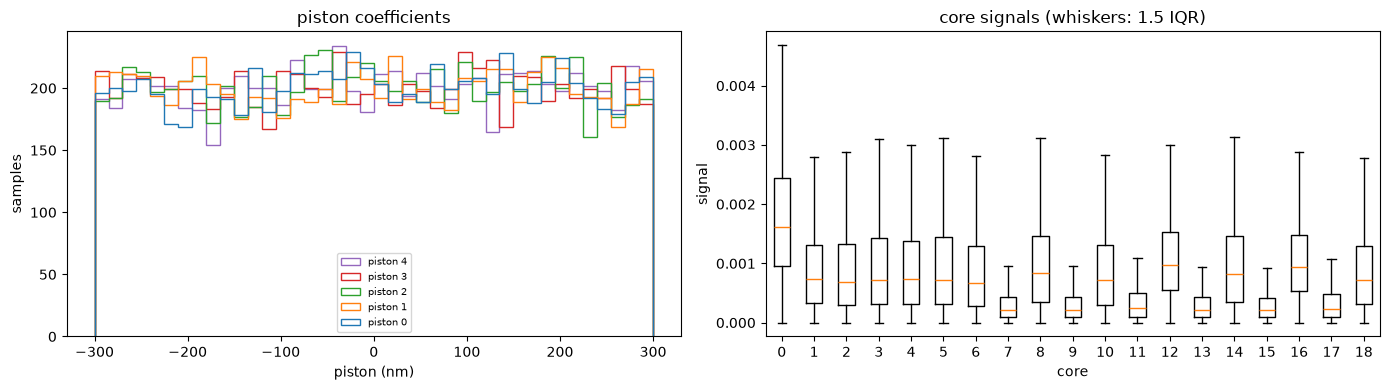

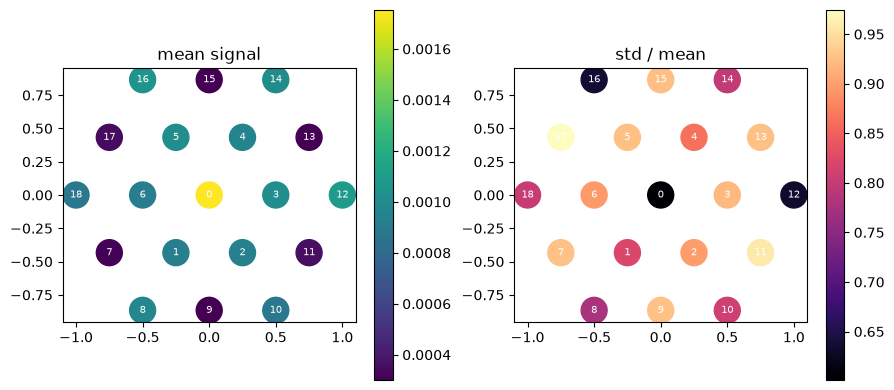

In [4]:
plot_single_overview(SA_tr, CA_tr, dsA.core_xy)

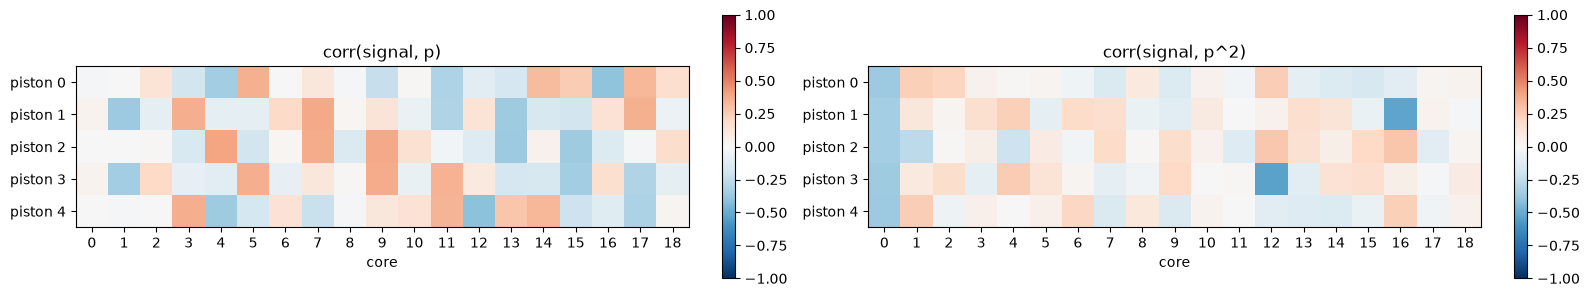

sum of the 19 signals per sample: mean 0.01528, std / mean 0.29%


In [5]:
plot_signal_piston_correlation(SA_tr, CA_tr)
tot = SA_tr.sum(axis=1)
print(f"sum of the 19 signals per sample: mean {tot.mean():.4g}, std / mean {tot.std() / tot.mean():.2%}")

## A2. Baseline: k-nearest neighbours

k-NN needs no training and shows how well the signals determine the pistons
at all.

In [6]:
from sklearn.neighbors import KNeighborsRegressor

knnA = cacheA("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(XA_tr, YA_tr))
score(RESULTS_A, "kNN", knnA.predict(XA_va), CA_va, ys=ysA)
DOF_A["kNN"] = n_dof(knnA)          # k-NN fits nothing: the training set it keeps

[cache] loaded kNN
kNN                    mean    29.42 nm   per piston [30.67 30.2  27.13 29.22 29.88]


## A3. MLP

Three hidden layers of 128 units, Adam, 500 epochs; the weights of the epoch
with the lowest validation loss are kept.

MLP [19, 128, 128, 128, 5]: best epoch 494 of 500
MLP                    mean     8.98 nm   per piston [9.15 9.43 9.24 7.64 9.45]


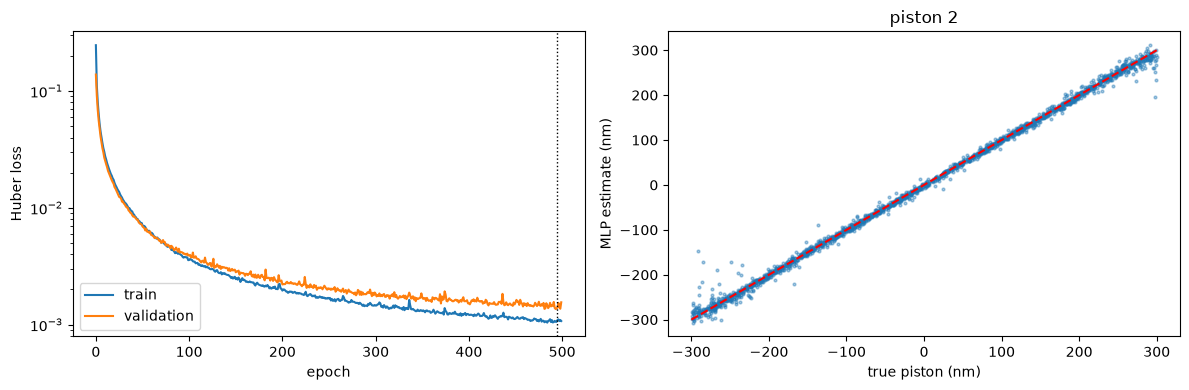

In [7]:
LAYERS_A = [XA_tr.shape[1], 128, 128, 128, M_MODES]
MLP_A = f"data/ml/cache_single/mlp-{'x'.join(map(str, LAYERS_A))}-e500.npz"
paramsA, histA = fit_or_load_mlp(MLP_A, LAYERS_A, XA_tr, YA_tr, XA_va, YA_va, epochs=500, lr=3e-4,
                                 retrain=RETRAIN)
CA_mlp = ysA.inverse(np.asarray(ml.mlp_forward(paramsA, XA_va)))
score(RESULTS_A, "MLP", CA_mlp, CA_va)
DOF_A["MLP"] = n_dof(paramsA)
plot_mlp(histA, CA_va, CA_mlp, k=2, span=A_SPAN_NM)

## A4. Polynomial models

### Sparse degree-3 polynomial (ElasticNet)

All 1539 monomials of degree <= 3 in the 19 core signals, standardised, with
an ElasticNet whose L1 part zeroes most of them (penalty chosen by 5-fold
cross-validation).

In [8]:
from sklearn.linear_model import ElasticNetCV

Z3A_tr, Z3A_va, _, _ = ml.poly_features(XA_tr, XA_va, 3)
elasticA = cacheA("elastic-d3", lambda: [
    ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.8, 1.0], max_iter=100000, cv=5,
                 n_jobs=-1, random_state=0).fit(Z3A_tr, YA_tr[:, k]) for k in range(M_MODES)])
print("non-zero terms per piston:", [int(np.count_nonzero(m.coef_)) for m in elasticA])
score(RESULTS_A, "elastic-d3", np.stack([m.predict(Z3A_va) for m in elasticA], axis=1), CA_va, ys=ysA)
DOF_A["elastic-d3"] = n_dof(elasticA)

[cache] loaded elastic-d3
non-zero terms per piston: [846, 879, 848, 879, 827]
elastic-d3             mean    25.47 nm   per piston [26.15 24.24 25.51 22.95 28.51]


### Zernike representation of the core signals

The 19 signals, placed at their cores on the unit disk, projected onto Noll
Zernikes. With 19 cores the sampled basis has rank 19, so this is a change of
variables rather than a compression: the degree-3 polynomials of the Zernike
coefficients span the same functions as those of the raw signals, and the
two representations differ only in how the fits below regularise and select
terms.

Zernike basis (19, 36), rank 19


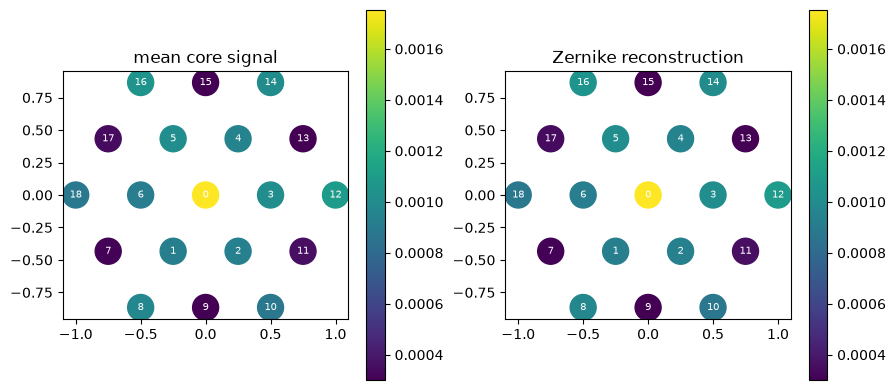

In [9]:
N_ZERN = 36
ZBASIS, znames = ml.zernike_basis(dsA.core_xy, N_ZERN, fill=0.8)
ZPROJ = ml.modal_projector(ZBASIS)
print(f"Zernike basis {ZBASIS.shape}, rank {np.linalg.matrix_rank(ZBASIS)}")

zstdA = ml.Standardizer(eps=1e-9).fit(SA_tr @ ZPROJ.T)
ZA_tr, ZA_va = zstdA.transform(SA_tr @ ZPROJ.T), zstdA.transform(SA_va @ ZPROJ.T)

s_mean = SA_tr.mean(axis=0)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
hexmap(ax[0], dsA.core_xy, s_mean, "mean core signal")
hexmap(ax[1], dsA.core_xy, ZBASIS @ (ZPROJ @ s_mean), "Zernike reconstruction")
plt.tight_layout(); plt.show()

### Dense degree-3 polynomial ridge: Zernike vs. raw core signals

In [10]:
for tag, F_tr, F_va in [("zern-d3", ZA_tr, ZA_va), ("fiber-d3", XA_tr, XA_va)]:
    model = cacheA(tag, lambda F_tr=F_tr: ml.fit_dense_poly_ridge(F_tr, YA_tr, 3))
    DOF_A[tag] = n_dof(model)
    score(RESULTS_A, tag, ml.predict_dense_poly_ridge(model, F_va), CA_va, ys=ysA,
          note=f"   ({model[0].n_output_features_} terms)")

[cache] loaded zern-d3
zern-d3                mean    11.34 nm   per piston [12.29 10.89  8.88 11.38 13.26]   (9138 terms)
[cache] loaded fiber-d3
fiber-d3               mean    11.49 nm   per piston [12.62 10.88  9.08 11.3  13.55]   (1539 terms)


### Compact model: OMP with a term budget K

Orthogonal Matching Pursuit keeps at most K of the 9138 degree-3 monomials of
the Zernike coefficients per piston (after screening them by correlation
with the piston). The sweep shows the accuracy / size trade-off.

In [11]:
SCREEN_A = 9000
KS_A = [100, 200, 300, 400, 500, 600, 750, 900, 1050, 1150, 1282]
RECORD_KS_A = (500, 1282)

Zd3A_tr, Zd3A_va, _, poly_d3A = ml.poly_features(ZA_tr, ZA_va, 3)
omp_fits_A = lambda K: omp_fits(cacheA, "zern-omp", Zd3A_tr, YA_tr, K, SCREEN_A)
sweepA = omp_sweep(cacheA, "zern-omp", Zd3A_tr, YA_tr, Zd3A_va, CA_va, ysA, KS_A, SCREEN_A)

[cache] loaded zern-omp-K100
K=  100:   100.0 terms/piston   mean RMSE  53.7 nm
[cache] loaded zern-omp-K200
K=  200:   200.0 terms/piston   mean RMSE  42.7 nm
[cache] loaded zern-omp-K300
K=  300:   300.0 terms/piston   mean RMSE  36.9 nm
[cache] loaded zern-omp-K400
K=  400:   400.0 terms/piston   mean RMSE  32.9 nm
[cache] loaded zern-omp-K500
K=  500:   500.0 terms/piston   mean RMSE  29.5 nm
[cache] loaded zern-omp-K600
K=  600:   600.0 terms/piston   mean RMSE  27.1 nm
[cache] loaded zern-omp-K750
K=  750:   750.0 terms/piston   mean RMSE  23.4 nm
[cache] loaded zern-omp-K900
K=  900:   900.0 terms/piston   mean RMSE  20.5 nm
[cache] loaded zern-omp-K1050
K= 1050:  1050.0 terms/piston   mean RMSE  17.1 nm
[cache] loaded zern-omp-K1150
K= 1150:  1150.0 terms/piston   mean RMSE  14.4 nm
[cache] loaded zern-omp-K1282
K= 1282:  1280.2 terms/piston   mean RMSE   8.4 nm


[cache] loaded zern-omp-K500
zern-omp-K500          mean    29.48 nm   per piston [29.36 29.67 29.44 26.5  32.44]
[cache] loaded zern-omp-K500
[cache] loaded zern-omp-K1282
zern-omp-K1282         mean     8.41 nm   per piston [8.91 7.89 8.27 8.04 8.94]
[cache] loaded zern-omp-K1282


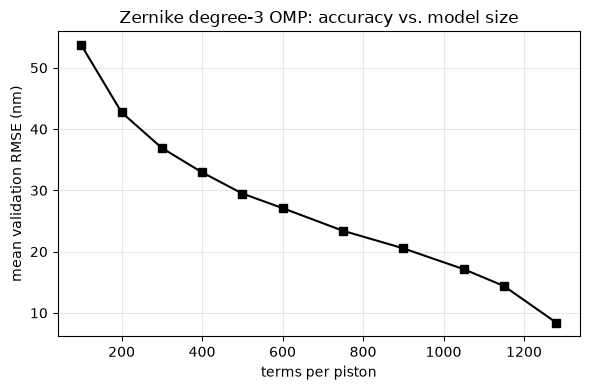

In [12]:
for K in RECORD_KS_A:
    score(RESULTS_A, f"zern-omp-K{K}", omp_predict_all(Zd3A_va, omp_fits_A(K)), CA_va, ys=ysA)
    DOF_A[f"zern-omp-K{K}"] = n_dof(omp_fits_A(K))
plot_omp_sweep(sweepA, "Zernike degree-3 OMP: accuracy vs. model size")

## A5. What the OMP models use

### Which monomials does OMP keep?

Kept vs. available monomials per degree at K = 500, and how the degree mix of
the kept terms changes with the budget.

In [13]:
K_TABLE, KS_MIX = 500, [100, 200, 300, 400, 500]
degree = poly_d3A.powers_.sum(axis=1)
degs = np.arange(1, degree.max() + 1)
total = np.array([(degree == d).sum() for d in degs])
kept = kept_by_degree(omp_fits_A(K_TABLE), degree)
print(f"K = {K_TABLE}: kept / available monomials per degree (one column per piston)")
for i, d in enumerate(degs):
    print(f"  degree {d}: {total[i]:5d} available, kept {kept[:, i]}  ({kept[:, i].mean() / total[i]:.1%})")

[cache] loaded zern-omp-K500
K = 500: kept / available monomials per degree (one column per piston)
  degree 1:    36 available, kept [ 6  8  5  5 11]  (19.4%)
  degree 2:   666 available, kept [54 49 56 58 52]  (8.1%)
  degree 3:  8436 available, kept [440 443 439 437 437]  (5.2%)


[cache] loaded zern-omp-K100
[cache] loaded zern-omp-K200
[cache] loaded zern-omp-K300
[cache] loaded zern-omp-K400
[cache] loaded zern-omp-K500


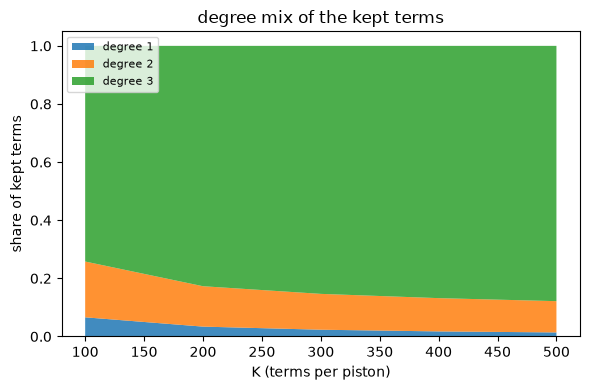

In [14]:
mix = np.array([kept_by_degree(omp_fits_A(K), degree).sum(axis=0) for K in KS_MIX], float)
plot_degree_mix(KS_MIX, (mix / mix.sum(axis=1, keepdims=True)).T)

### Which Zernike coefficients matter?

For the K = 1282 model: the total |coefficient| (in standardised units) of
the monomials each Zernike coefficient appears in, per piston.

[cache] loaded zern-omp-K1282


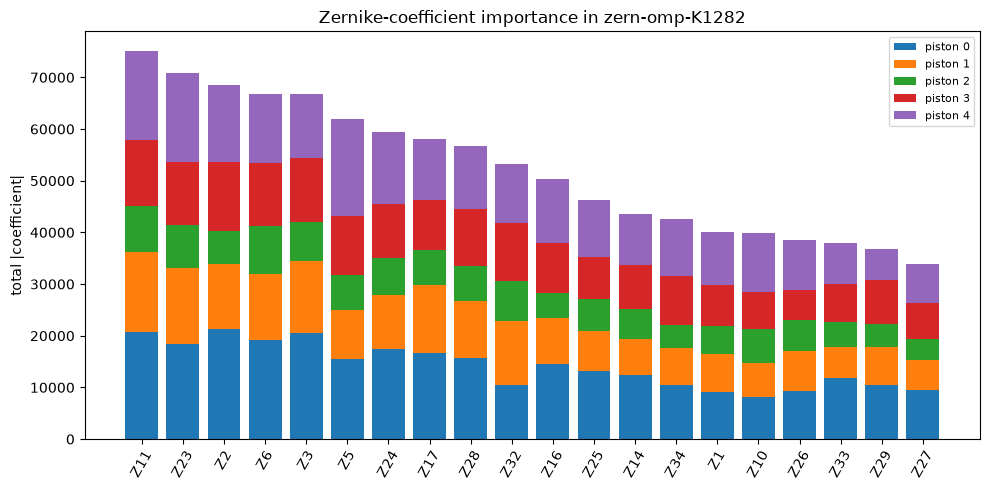

In [15]:
K = 1282
mass = omp_variable_importance(omp_fits_A(K), poly_d3A.powers_)   # (piston, Zernike coefficient)
plot_stacked_importance(mass, znames, f"Zernike-coefficient importance in zern-omp-K{K}")

## A6. Part A comparison

  zern-omp-K500             29.48 nm   per piston [29.36 29.67 29.44 26.5  32.44]       2,505 dof
  kNN                       29.42 nm   per piston [30.67 30.2  27.13 29.22 29.88]     192,000 dof
  elastic-d3                25.47 nm   per piston [26.15 24.24 25.51 22.95 28.51]       4,284 dof
  fiber-d3                  11.49 nm   per piston [12.62 10.88  9.08 11.3  13.55]       7,700 dof
  zern-d3                   11.34 nm   per piston [12.29 10.89  8.88 11.38 13.26]      45,695 dof
  MLP                        8.98 nm   per piston [9.15 9.43 9.24 7.64 9.45]      36,229 dof
  zern-omp-K1282             8.41 nm   per piston [8.91 7.89 8.27 8.04 8.94]       6,406 dof


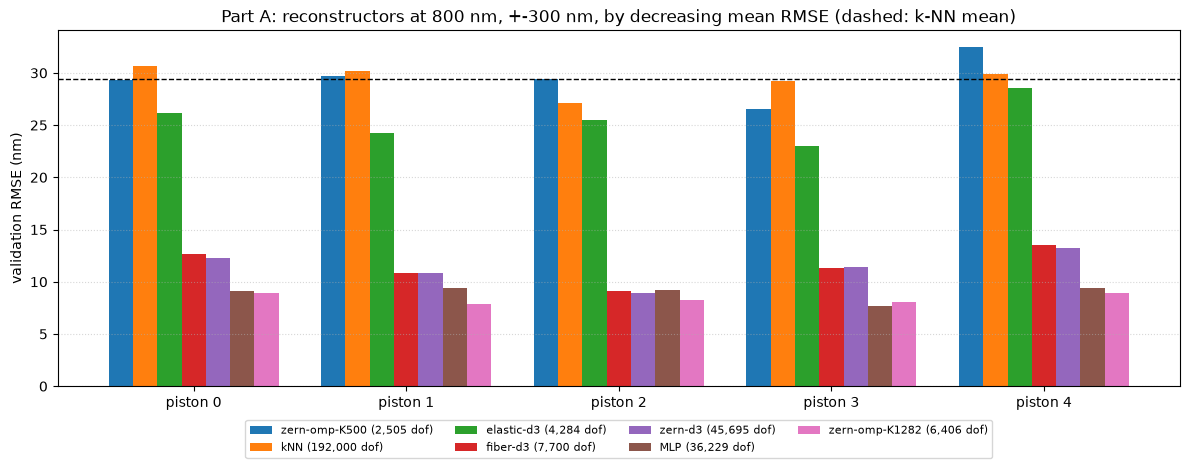

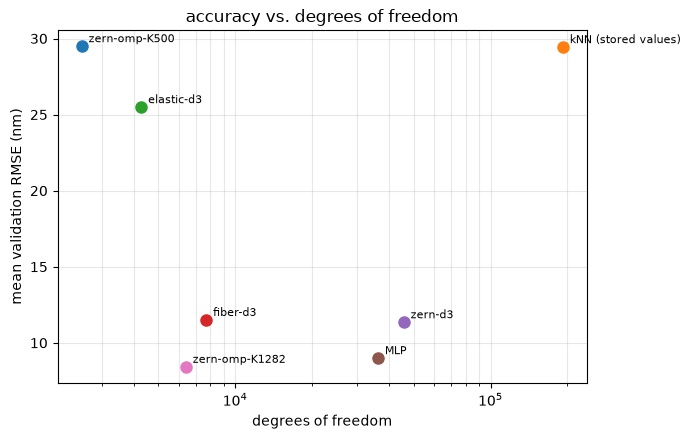

In [16]:
show_results(RESULTS_A, "Part A: reconstructors at 800 nm, +-300 nm, by decreasing mean RMSE "
             "(dashed: k-NN mean)", ref="kNN", logy=False, sort=True, dof=DOF_A)

# Part B: 41 wavelengths (700-900 nm, +-5 um)

Origin: `trainMLP_multiwavelength.ipynb` (single models on the whole
spectrum) and `PL19_EML.ipynb` (per-wavelength models and the unwrap).

## B1. Dataset

One lantern characterization per wavelength (cached in cbeam's
`examples/data/`), then all samples propagated wavelength by wavelength
(`ml_reconstruct.simulate.simulate_spectra`). Each signal is the power in
one output channel as a fraction of the incident power, so it includes the
input coupling efficiency. Simulating 50000 samples at 41 wavelengths in one
process takes many hours; `data/gen/` has the chunked, restartable
generation used for the current file (about 3.3 h on 12 processes).

The signals are standardised per (wavelength, core) column with the
training statistics. `XB_*` is the flat 779-long view used by the
full-spectrum models, `X3B_*` the same numbers as (n, wavelength, core) for
the per-wavelength models.

In [17]:
B_SAMPLES, B_TRAIN = 50000, 40000
B_SPAN_NM = 5000.0
WAVELENGTHS_NM = np.linspace(700.0, 900.0, 41)
B_DATASET = "data/ml/spectral_41wl.npz"
cacheB = ml.ModelCache("data/ml/cache_spectral", retrain=RETRAIN)     # full-spectrum models
cacheW = ml.ModelCache("data/ml/cache_perlambda", retrain=RETRAIN)    # per-wavelength and global OMP
# simulated (with rng=0) only if the file is missing: hours, see data/gen/ for a parallel run
dsB = load_or_simulate(B_DATASET, "make_spectral_dataset", n=B_SAMPLES, n_train=B_TRAIN,
                       span_nm=B_SPAN_NM, wavelengths_nm=WAVELENGTHS_NM)

In [18]:
SB_tr, CB_tr = dsB.train
SB_va, CB_va = dsB.val
lam = dsB.wavelengths_nm
n_wl, n_cores = SB_tr.shape[1:]
xsB, ysB = ml.Standardizer().fit(SB_tr.reshape(len(SB_tr), -1)), ml.Standardizer().fit(CB_tr)
XB_tr = xsB.transform(SB_tr.reshape(len(SB_tr), -1))
XB_va = xsB.transform(SB_va.reshape(len(SB_va), -1))
X3B_tr, X3B_va = XB_tr.reshape(SB_tr.shape), XB_va.reshape(SB_va.shape)
YB_tr, YB_va = ysB.transform(CB_tr), ysB.transform(CB_va)
print(f"{len(XB_tr)} training / {len(XB_va)} validation samples, {n_wl} wavelengths "
      f"({lam[0]:.0f}-{lam[-1]:.0f} nm) x {n_cores} cores = {XB_tr.shape[1]} inputs; "
      f"pistons std {CB_tr.std():.0f} nm")

40000 training / 10000 validation samples, 41 wavelengths (700-900 nm) x 19 cores = 779 inputs; pistons std 2883 nm


In [19]:
RESULTS_B, DOF_B = {}, {}   # model -> per-piston validation RMSE [nm], degrees of freedom
score(RESULTS_B, "no skill (mean)", np.broadcast_to(CB_tr.mean(0), CB_va.shape), CB_va)
DOF_B["no skill (mean)"] = M_MODES

no skill (mean)        mean  2893.08 nm   per piston [2888.28 2880.81 2891.36 2908.63 2896.31]


## B1b. A look at the dataset

The rows below cover:

- **Total channel power vs. wavelength.** The total for the random pistons
  of the training set, compared with a flat wavefront when the ramp results
  of `multi_wavelength.ipynb` are available. The step changes between
  neighbouring wavelengths are an open question (see `HANDOVER.md`): the
  input mode that ends up as the dropped cladding mode probably changes near
  mode crossings.
- **One sample's 19 spectra.**
- **Mean channel power and relative variation, per (wavelength, core).**
- **How much each wavelength sees each piston, linearly.** This is the R^2 of
  a linear fit of the piston's phasor (sin, cos)(2 pi p / lambda) on the 19
  channel powers at that wavelength, averaged over sin and cos, on a quarter
  of the training rows. It ignores everything a nonlinear model can add.

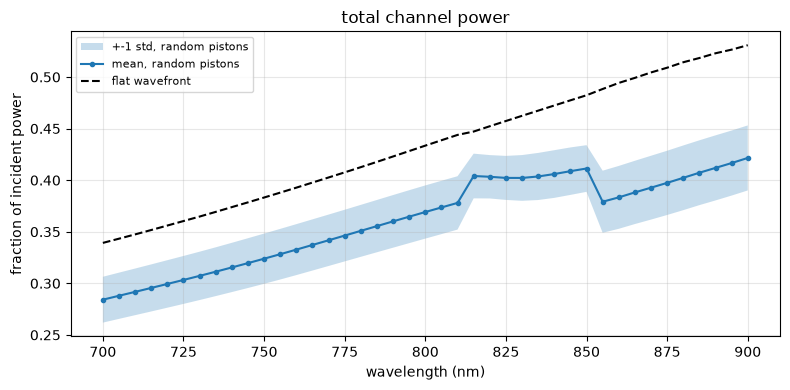

largest steps of the mean total power between neighbouring wavelengths:
  850 -> 855 nm: 0.411 -> 0.379
  810 -> 815 nm: 0.378 -> 0.404
  895 -> 900 nm: 0.417 -> 0.422


In [20]:
m_tot = plot_total_power(lam, SB_tr, ramp_file="data/ml/mw_ramp_41.npz")   # ramp: multi_wavelength.ipynb
print("largest steps of the mean total power between neighbouring wavelengths:")
for j in np.argsort(-np.abs(np.diff(m_tot)))[:3]:
    print(f"  {lam[j]:.0f} -> {lam[j + 1]:.0f} nm: {m_tot[j]:.3f} -> {m_tot[j + 1]:.3f}")

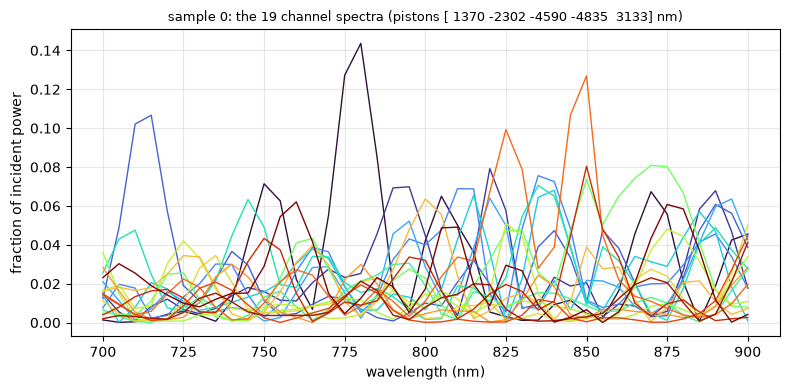

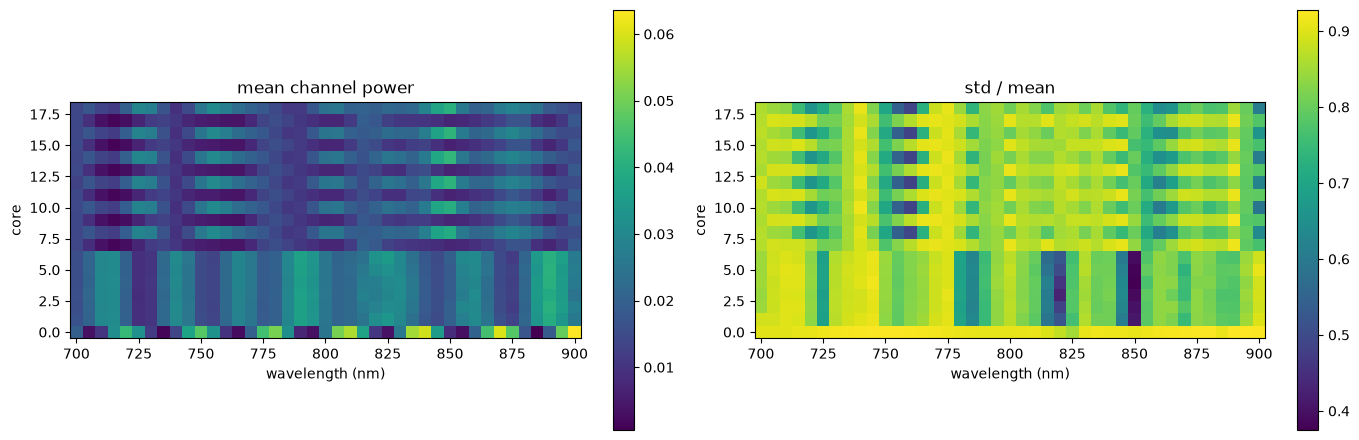

In [21]:
plot_sample_spectra(lam, SB_tr, CB_tr, i=0)
plot_spectral_maps(lam, SB_tr)

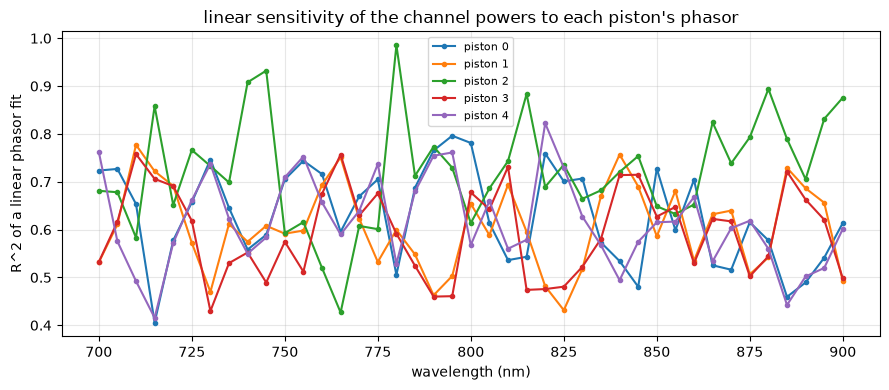

In [22]:
rows_s = ml.subsample_rows(len(SB_tr), 0.25, seed=2)
R2 = phasor_r2(X3B_tr[rows_s], CB_tr[rows_s], lam)
plot_per_piston(lam, R2, "wavelength (nm)", "R^2 of a linear phasor fit",
                "linear sensitivity of the channel powers to each piston's phasor")

## B2. Single models on the whole spectrum

### k-nearest neighbours

In [23]:
from sklearn.neighbors import KNeighborsRegressor

knnB = cacheB("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(XB_tr, YB_tr))
score(RESULTS_B, "kNN", knnB.predict(XB_va), CB_va, ys=ysB)
DOF_B["kNN"] = n_dof(knnB)

[cache] loaded kNN
kNN                    mean  1230.98 nm   per piston [1255.73 1213.16 1202.58 1254.91 1228.52]


### Dense degree-2 polynomial ridge on a wavelength subset

Every degree-2 monomial of the core signals at every `WL_STRIDE`-th
wavelength (raw signals, or their per-wavelength Zernike projection with
`REPR = "zern"`), one ridge per piston. The number of terms grows
quadratically with the inputs and the memory linearly with the rows, so the
fit uses a random `DATA_SHARE` of the training and validation rows, and
checks the memory needed first. It is scored on that validation subset only.

In [24]:
REPR, WL_STRIDE, DEGREE_R = "fiber", 4, 2
DATA_SHARE_R, MEM_BUDGET_GIB = 0.15, 128.0
wl_fit = np.arange(0, n_wl, WL_STRIDE)

proj_R = ml.modal_projector(ml.zernike_basis(dsB.core_xy, 18, fill=0.8)[0]) if REPR == "zern" else None
to_features = lambda S: spectral_features(S, wl_fit, proj_R)
fsB = ml.Standardizer(eps=1e-9).fit(to_features(SB_tr))
fit_rows = ml.subsample_rows(len(SB_tr), DATA_SHARE_R, seed=0)
val_rows = ml.subsample_rows(len(SB_va), DATA_SHARE_R, seed=1)
F_fit, F_val = fsB.transform(to_features(SB_tr[fit_rows])), fsB.transform(to_features(SB_va[val_rows]))

In [25]:
n_terms_R = ml.n_poly_terms(F_fit.shape[1], DEGREE_R)
need_gib = (1.5 * len(F_fit) + len(F_val)) * n_terms_R * 8 / 2**30   # RidgeCV needs ~0.5x Z_fit extra
print(f"{len(wl_fit)} wavelengths x {F_fit.shape[1] // len(wl_fit)} {REPR} = {F_fit.shape[1]} inputs "
      f"-> {n_terms_R:,} terms; {len(F_fit)} fit / {len(F_val)} val rows -> ~{need_gib:.1f} GiB")
assert need_gib <= MEM_BUDGET_GIB, "lower DATA_SHARE_R (linear) or raise WL_STRIDE (quadratic)"

ridgeB = cacheB(f"{REPR}-ridge-d{DEGREE_R}-w{len(wl_fit)}-n{len(F_fit)}",
                lambda: ml.fit_dense_poly_ridge(F_fit, YB_tr[fit_rows], DEGREE_R, alphas=np.logspace(-2, 6, 17)))
DOF_B[f"{REPR}-ridge-d{DEGREE_R}"] = n_dof(ridgeB)
score(RESULTS_B, f"{REPR}-ridge-d{DEGREE_R}", ysB.inverse(ml.predict_dense_poly_ridge(ridgeB, F_val)),
      CB_va[val_rows], note=f"   (on {len(val_rows)} validation rows)");

11 wavelengths x 19 fiber = 209 inputs -> 22,154 terms; 6000 fit / 1500 val rows -> ~1.7 GiB
[cache] loaded fiber-ridge-d2-w11-n6000
fiber-ridge-d2         mean   969.00 nm   per piston [ 983.26 1060.86  733.52 1021.48 1045.85]   (on 1500 validation rows)


### One global polynomial model (OMP)

A single degree-3 OMP model per piston on the core signals of several
wavelengths at once, regressing the piston directly. The number of terms
grows as (inputs)^3, so only a subset of wavelengths and cores fits in
memory. It is fitted on the same 20% of the training rows as the
per-wavelength models of B3.

In [26]:
DATA_SHARE_W = 0.2
rows_W = ml.subsample_rows(len(X3B_tr), DATA_SHARE_W, seed=0)   # shared with B3

WL_G, FIB_G, K_G, SCREEN_G = np.arange(0, n_wl, 8), np.arange(0, n_cores, 2), 1000, 6000
F_tr = X3B_tr[rows_W][:, WL_G][:, :, FIB_G].reshape(len(rows_W), -1)
F_va = X3B_va[:, WL_G][:, :, FIB_G].reshape(len(X3B_va), -1)
print(f"{len(WL_G)} wavelengths x {len(FIB_G)} cores = {F_tr.shape[1]} inputs -> "
      f"{ml.n_poly_terms(F_tr.shape[1], 3):,} degree-3 terms, {len(rows_W)} training rows")
globB = cacheW(f"global-d3-K{K_G}-w{len(WL_G)}-f{len(FIB_G)}-n{len(rows_W)}",
               lambda: ml.fit_omp_poly(F_tr, CB_tr[rows_W], 3, K_G, SCREEN_G))
score(RESULTS_B, "global OMP", ml.predict_omp_poly(globB, F_va), CB_va)
DOF_B["global OMP"] = n_dof(globB)

6 wavelengths x 10 cores = 60 inputs -> 39,710 degree-3 terms, 8000 training rows
[cache] loaded global-d3-K1000-w6-f10-n8000
global OMP             mean  2306.45 nm   per piston [2371.59 2395.21 1958.4  2395.36 2411.69]


### MLP on the full spectrum

Four hidden layers of 256 units on all 779 inputs, Adam, 10000 epochs (about
5 minutes on a GPU). Piston 2 dominates its error, and the best epoch comes
late in the run, so it may not have finished converging.

MLP [779, 256, 256, 256, 256, 5]: best epoch 9732 of 10000
MLP (all wl)           mean    10.24 nm   per piston [ 6.53  5.11 25.2   6.84  7.52]


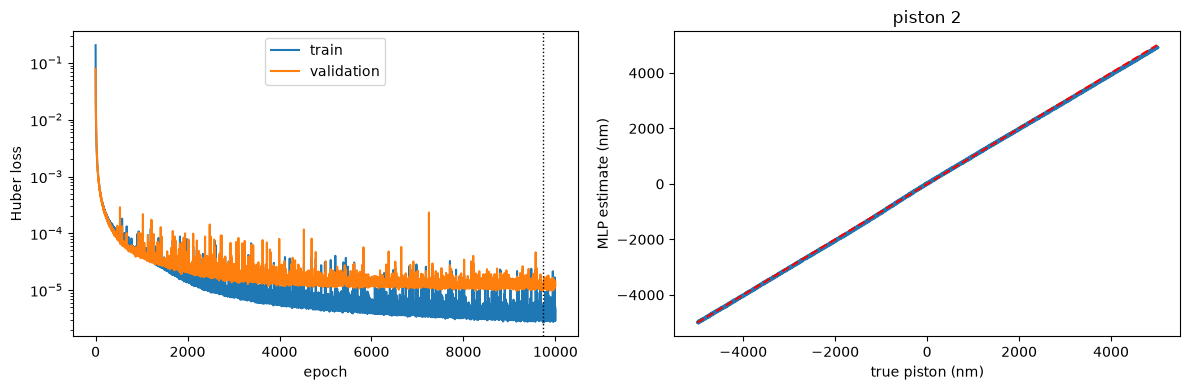

In [27]:
LAYERS_B = [XB_tr.shape[1], 256, 256, 256, 256, M_MODES]
EPOCHS_B, LR_B = 10000, 3e-4
MLP_B = f"data/ml/cache_spectral/mlp-{'x'.join(map(str, LAYERS_B))}-e{EPOCHS_B}-lr{LR_B:g}.npz"
paramsB, histB = fit_or_load_mlp(MLP_B, LAYERS_B, XB_tr, YB_tr, XB_va, YB_va, epochs=EPOCHS_B, lr=LR_B,
                                 retrain=RETRAIN)
CB_mlp = ysB.inverse(np.asarray(ml.mlp_forward(paramsB, XB_va)))
score(RESULTS_B, "MLP (all wl)", CB_mlp, CB_va)
DOF_B["MLP (all wl)"] = n_dof(paramsB)
plot_mlp(histB, CB_va, CB_mlp, k=2, span=B_SPAN_NM, s=2)

## B3. Per-wavelength models of the wrapped piston

At wavelength lambda the signals depend on a piston only modulo lambda (the
pupil phase is 2 pi p / lambda). So one degree-3 OMP polynomial (at most K
terms) of the core signals per wavelength in `WL_USE` regresses the phasor
(sin, cos)(2 pi p / T) of each piston wrapped at the period T = lambda, on
the training rows `rows_W`.

In [28]:
WRAP_FACTOR = 1.0                  # period = WRAP_FACTOR * lambda (0.5 also works, same accuracy:
                                   # a function of p mod lambda/2 is one of p mod lambda)
WL_USE = np.arange(0, n_wl, 2)     # 21 of the 41 wavelengths
FIB_USE = np.arange(n_cores)       # all 19 cores
DEGREE_W, K_W, SCREEN_W = 3, 1000, 2000   # SCREEN_W >= 1539 terms: no screening at degree 3 / 19 inputs

periods = lam * WRAP_FACTOR
TAG_W = f"wrap{WRAP_FACTOR:g}-d{DEGREE_W}-K{K_W}-f{len(FIB_USE)}-n{len(rows_W)}"
fitW = ml.fit_wrapped_models(
    X3B_tr, X3B_va, CB_tr, CB_va, periods, WL_USE, FIB_USE, degree=DEGREE_W, K=K_W, screen=SCREEN_W,
    cache=cacheW, rows=rows_W, tag=TAG_W)
print(f"{len(WL_USE)} per-wavelength models ({fitW['seconds']:.0f} s)")

[cache] loaded wrap1-d3-K1000-f19-n8000-w0
[cache] loaded wrap1-d3-K1000-f19-n8000-w2
[cache] loaded wrap1-d3-K1000-f19-n8000-w4
[cache] loaded wrap1-d3-K1000-f19-n8000-w6
[cache] loaded wrap1-d3-K1000-f19-n8000-w8
[cache] loaded wrap1-d3-K1000-f19-n8000-w10
[cache] loaded wrap1-d3-K1000-f19-n8000-w12
[cache] loaded wrap1-d3-K1000-f19-n8000-w14
[cache] loaded wrap1-d3-K1000-f19-n8000-w16
[cache] loaded wrap1-d3-K1000-f19-n8000-w18
[cache] loaded wrap1-d3-K1000-f19-n8000-w20
[cache] loaded wrap1-d3-K1000-f19-n8000-w22
[cache] loaded wrap1-d3-K1000-f19-n8000-w24
[cache] loaded wrap1-d3-K1000-f19-n8000-w26
[cache] loaded wrap1-d3-K1000-f19-n8000-w28
[cache] loaded wrap1-d3-K1000-f19-n8000-w30
[cache] loaded wrap1-d3-K1000-f19-n8000-w32
[cache] loaded wrap1-d3-K1000-f19-n8000-w34
[cache] loaded wrap1-d3-K1000-f19-n8000-w36
[cache] loaded wrap1-d3-K1000-f19-n8000-w38
[cache] loaded wrap1-d3-K1000-f19-n8000-w40
21 per-wavelength models (35 s)


wrapped-piston RMSE per wavelength [nm]  (chance ~ period / sqrt(12))
   lambda | +-T/2 |    p0    p1    p2    p3    p4
    700.0 |   350 |   7.5   8.1   6.9   7.5   7.5
    710.0 |   355 |   9.8   9.2   8.1   9.5  10.5
    720.0 |   360 |   9.3   9.7   4.6   9.7   9.6
    730.0 |   365 |  10.6  11.9   9.2  11.1  11.1
    740.0 |   370 |  10.1  11.2   4.1  10.7  10.0
    750.0 |   375 |   8.1   8.8   6.0   8.8   8.4
    760.0 |   380 |  11.7  11.7   8.3  11.9  12.3
    770.0 |   385 |   9.3   8.8   6.0   8.5   9.2
    780.0 |   390 |   7.0   6.9   0.5   6.6   7.1
    790.0 |   395 |   6.4   8.3   3.2   8.2   6.5
    800.0 |   400 |  10.3   9.7   6.8  10.2  10.4
    810.0 |   405 |  10.0  10.0   3.6  10.3  10.6
    820.0 |   410 |   5.1   5.9   3.7   5.5   5.4
    830.0 |   415 |   7.9   9.8   6.6   9.4   9.9
    840.0 |   420 |   9.5   8.7   6.2   7.6   9.8
    850.0 |   425 |  10.9  10.0   4.4   9.5  11.2
    860.0 |   430 |   9.0   9.3   7.6   9.4   8.7
    870.0 |   435 |   9.7   9.

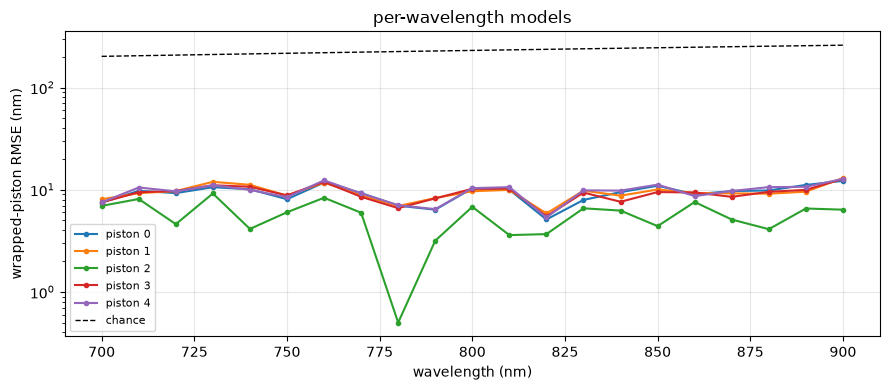

In [29]:
print_wrapped_table(fitW, lam)
plot_per_piston(lam[WL_USE], fitW["sig_va"], "wavelength (nm)", "wrapped-piston RMSE (nm)",
                "per-wavelength models", logy=True, ref=fitW["periods"] / np.sqrt(12), ref_label="chance")

## B4. Multi-wavelength unwrap

The wrapped estimates of all wavelengths in `WL_USE` are fused into the
full-range piston (`ml_reconstruct.unwrap`: a circular maximum-likelihood
search over the whole +-5 um range, then a robust refinement), as in
synthetic-wavelength interferometry. A "wrong fringe" is an error larger than
half the shortest period.

per-wl OMP + unwrap    mean     1.64 nm   per piston [1.88 1.99 0.45 1.9  1.96]

 piston | RMSE (nm) | bias (nm) | wrong fringe | best single wl, no unwrap
   0    |      1.88 |     -0.01 |       0.00% |      2906
   1    |      1.99 |     +0.02 |       0.00% |      2895
   2    |      0.45 |     +0.00 |       0.00% |      2910
   3    |      1.90 |     +0.01 |       0.00% |      2926
   4    |      1.96 |     +0.04 |       0.00% |      2911
  mean  |      1.64 |           |       0.00% |


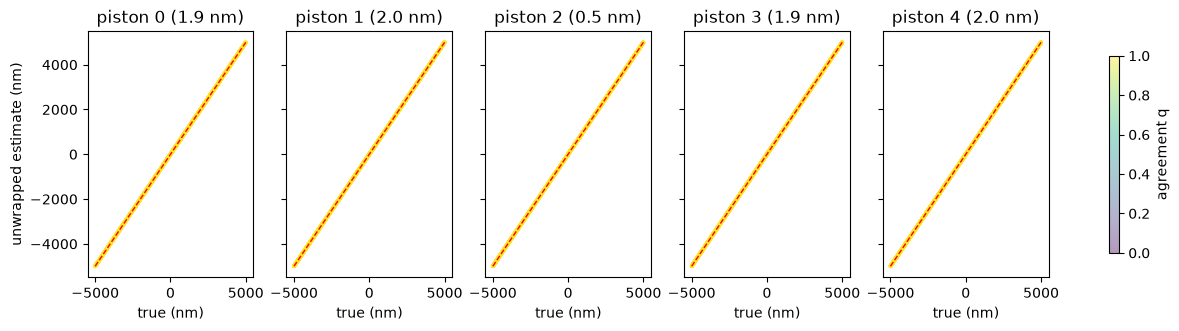

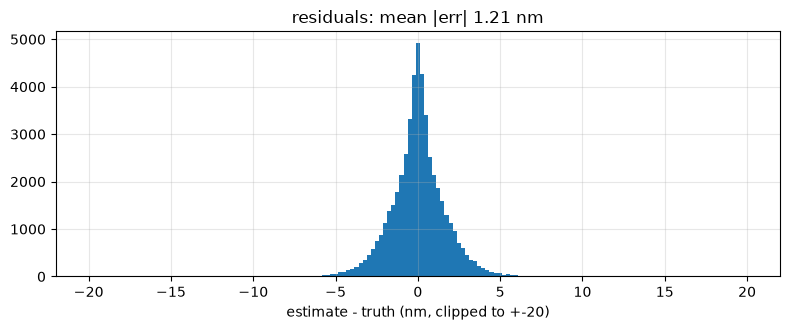

In [30]:
P_hat, Q = ml.unwrap_all(fitW, B_SPAN_NM)
score(RESULTS_B, "per-wl OMP + unwrap", P_hat, CB_va)
cacheW.verbose = False                 # summed over the per-wavelength models
DOF_B["per-wl OMP + unwrap"] = sum(n_dof(cacheW(f"{TAG_W}-w{w}", None)) for w in WL_USE)
cacheW.verbose = True
print()
print_unwrap_table(P_hat, CB_va, fitW)
plot_unwrap(P_hat, CB_va, Q, B_SPAN_NM)

## B5. Part B comparison

  no skill (mean)         2893.08 nm   per piston [2888.28 2880.81 2891.36 2908.63 2896.31]           5 dof
  kNN                     1230.98 nm   per piston [1255.73 1213.16 1202.58 1254.91 1228.52]   31,360,000 dof
  fiber-ridge-d2           969.00 nm   per piston [ 983.26 1060.86  733.52 1021.48 1045.85]     110,775 dof
  global OMP              2306.45 nm   per piston [2371.59 2395.21 1958.4  2395.36 2411.69]       5,005 dof
  MLP (all wl)              10.24 nm   per piston [ 6.53  5.11 25.2   6.84  7.52]     398,341 dof
  per-wl OMP + unwrap        1.64 nm   per piston [1.88 1.99 0.45 1.9  1.96]     210,210 dof


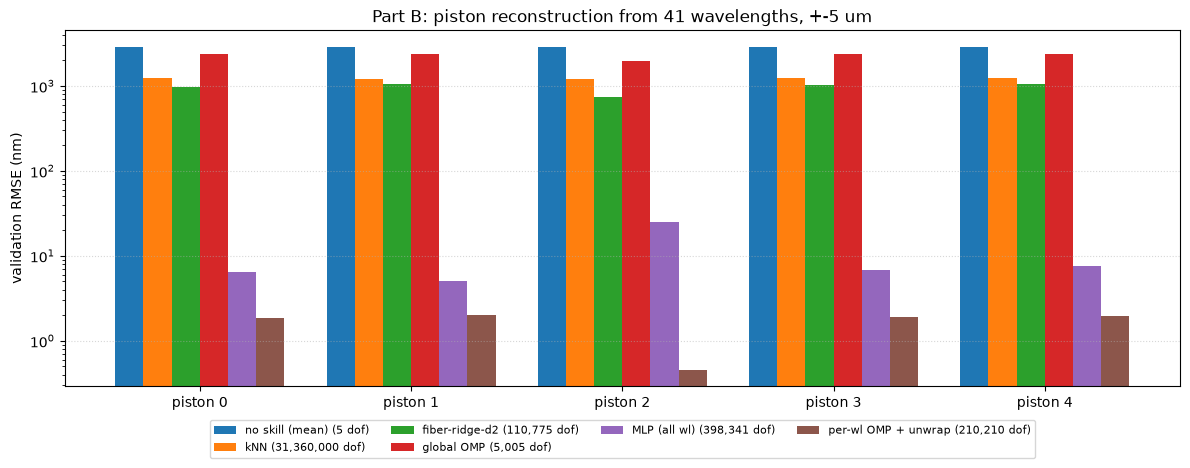

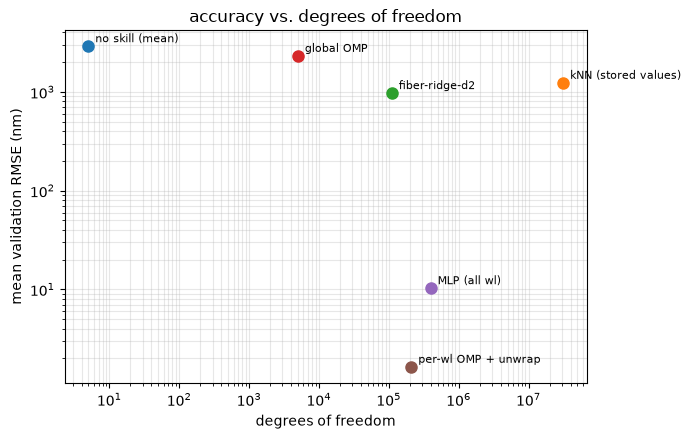

In [31]:
show_results(RESULTS_B, "Part B: piston reconstruction from 41 wavelengths, +-5 um", dof=DOF_B)

# Part C: what the MLP alone can achieve

MLPs at every sampling of the wavelength axis:

| scenario | inputs | pistons | |
|---|---|---|---|
| `800nm` | 19 cores at 800 nm | +-300 nm | Part A's dataset: inside the single-wavelength capture range |
| `1wl-800` | 19 cores at 800 nm | +-5 um | one wavelength of Part B's dataset: far outside it |
| `20nm` | 19 cores x 11 wavelengths (700-900 nm, 20 nm steps) | +-5 um | |
| `10nm` | 19 x 21 wavelengths (10 nm steps) | +-5 um | |
| `5nm` | 19 x 41 wavelengths (5 nm steps) | +-5 um | Part B's full spectrum |

With several wavelengths there are two approaches:

- **Full-spectrum MLP.** One network on the channel powers of all the
  scenario's wavelengths, regressing the pistons directly (as in B2).
- **Per-wavelength MLPs + unwrap.** One small network per wavelength on its 19
  channel powers, regressing each piston's phasor (sin, cos)(2 pi p / lambda),
  that is the piston wrapped at that wavelength. The multi-wavelength unwrap
  of B4 then fuses the wavelengths. It is B3/B4 with MLPs in place of the OMP
  polynomials. The 20 and 10 nm wavelengths are subsets of the 41, so one set
  of 41 per-wavelength models serves all three spectral scenarios.

`scripts/mlp_hpo.py` runs a small hyperparameter search for both, to balance
size against accuracy:

- **Full-spectrum grid:** depth {2, 3, 4} x width {32, 64, 128, 256}, Adam
  with a learning rate decaying from 3e-4 on a cosine schedule. That's 2000
  epochs at 800 nm and 5000 with the spectra. A first attempt starting from
  1e-3 generalised much worse on the spectra (17-39 nm), so it was dropped;
  its two runs are in `data/ml/mlp_hpo_lr1e-3/`.
- **Reference runs:** the notebooks' recipe (constant 3e-4) on their
  architectures, and one 4 x 256 network in `1wl-800`.
- **Seed stage:** the best and the "balanced" full-spectrum configuration of
  each scenario (the fewest parameters within 10% of the best RMSE),
  retrained with two more seeds.
- **Per-wavelength MLPs:** 2 x 32, 2 x 64, 3 x 64 and 3 x 128, 2000 epochs at
  each of the 41 wavelengths, then unwrapped in each spectral scenario.

The best epochs, the picked configurations and the per-wavelength error
estimates the unwrap weights by all come from the last 10% of the training
split, held out from training. The validation split is used only to report,
so these numbers are not tuned on what they are scored on. The models of
Parts A and B did pick their best epoch on the validation split, and they
trained on 10% more rows. Run the search (a few hours on one GPU) with

    setsid nohup bash scripts/run_mlp_hpo.sh > data/ml/mlp_hpo/run.log 2>&1 < /dev/null & disown

This part only reads its results (`data/ml/mlp_hpo/`) and shows whatever has
finished.

In [32]:
HPO_DIR = "data/ml/mlp_hpo"
SCEN_C = {"800nm": "1 wl (800 nm), +-300 nm", "1wl-800": "1 wl (800 nm), +-5 um",
          "20nm": "11 wl, 20 nm steps", "10nm": "21 wl, 10 nm steps", "5nm": "41 wl, 5 nm steps"}
C_VAL_C = {"800nm": CA_va, "1wl-800": CB_va, "20nm": CB_va, "10nm": CB_va, "5nm": CB_va}
runs = load_hpo_runs(HPO_DIR)
print(f"{len(runs)} finished runs:", dict(runs.groupby("role").size()) if len(runs) else "none")

250 finished runs: {'data800': np.int64(15), 'grid': np.int64(48), 'perwl': np.int64(164), 'reference': np.int64(2), 'seed-best': np.int64(8), 'single-wl': np.int64(1), 'unwrap': np.int64(12)}


## C1. Full-spectrum MLP: the grid

Validation RMSE (seed 0) and parameter count of every grid configuration;
rows are depth x width.

In [33]:
display(hpo_pivot(runs, "val_rmse_mean", SCEN_C).round(1), hpo_pivot(runs, "n_params", SCEN_C))

scenario     800nm   20nm   10nm    5nm
depth width                            
2     32      30.1  231.1   85.7   82.5
      64      18.6  155.7   64.1   57.5
      128     13.2  116.4   53.5   47.4
      256      9.8  114.4   49.6   44.6
3     32      22.6  214.4  140.6  138.5
      64      12.6  102.2   62.6   64.5
      128      8.1   74.0   52.1   49.0
      256      5.8   79.5   47.0   50.4
4     32      18.6  215.3  102.0  154.3
      64      10.6  105.1   60.9   61.7
      128      5.8   60.7   41.0   34.5
      256      4.3   68.4   20.3   19.2

scenario        800nm      20nm      10nm       5nm
depth width                                        
2     32       1861.0    7941.0   14021.0   26181.0
      64       5765.0   17925.0   30085.0   54405.0
      128     19717.0   44037.0   68357.0  116997.0
      256     72197.0  120837.0  169477.0  266757.0
3     32       2917.0    8997.0   15077.0   27237.0
      64       9925.0   22085.0   34245.0   58565.0
      128     36229.0   60549.0   84869.0  133509.0
      256    137989.0  186629.0  235269.0  332549.0
4     32       3973.0   10053.0   16133.0   28293.0
      64      14085.0   26245.0   38405.0   62725.0
      128     52741.0   77061.0  101381.0  150021.0
      256    203781.0  252421.0  301061.0  398341.0

## C2. Per-wavelength MLPs

The wrapped-piston error of each architecture at each wavelength (to compare
with the OMP models of B3), then the unwrapped result per spectral scenario.
The parameters are summed over the scenario's wavelengths.

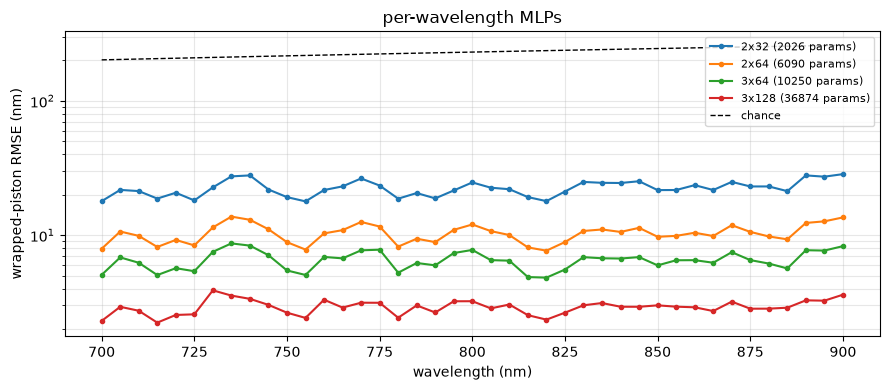

,scenario,config,n_models,n_params,es_rmse_mean,val_rmse_mean,val_wrong_fringe,val_rmse
0,10nm,2x32 cos3e-4 2000ep per-wl,21.0,42546,4.980,5.803,0.00002,"[9.539, 5.192, 3.626, 5.324, 5.336]"
1,10nm,2x64 cos3e-4 2000ep per-wl,21.0,127890,2.170,2.195,0.00000,"[2.314, 2.281, 1.747, 2.299, 2.336]"
2,10nm,3x64 cos3e-4 2000ep per-wl,21.0,215250,1.362,1.372,0.00000,"[1.414, 1.402, 1.213, 1.414, 1.419]"
3,10nm,3x128 cos3e-4 2000ep per-wl,21.0,774354,0.613,0.611,0.00000,"[0.617, 0.624, 0.558, 0.619, 0.635]"
4,20nm,2x32 cos3e-4 2000ep per-wl,11.0,22286,6.366,8.449,0.00008,"[17.122, 6.762, 4.53, 6.975, 6.857]"
5,20nm,2x64 cos3e-4 2000ep per-wl,11.0,66990,2.819,2.842,0.00000,"[3.04, 2.963, 2.207, 2.974, 3.024]"
6,20nm,3x64 cos3e-4 2000ep per-wl,11.0,112750,1.816,1.814,0.00000,"[1.866, 1.885, 1.569, 1.868, 1.883]"
7,20nm,3x128 cos3e-4 2000ep per-wl,11.0,405614,0.830,0.820,0.00000,"[0.821, 0.838, 0.738, 0.837, 0.864]"
8,5nm,2x32 cos3e-4 2000ep per-wl,41.0,83066,4.098,4.081,0.00000,"[4.373, 4.356, 2.799, 4.45, 4.429]"
9,5nm,2x64 cos3e-4 2000ep per-wl,41.0,249690,1.704,1.713,0.00000,"[1.802, 1.781, 1.305, 1.805, 1.869]"


In [34]:
plot_perwl_wrapped(runs)
display(hpo_unwrap_table(runs))

## C3. Accuracy vs. size, both approaches

One panel per scenario. Each coloured line is one depth of the full-spectrum
grid, labelled with its widths. The star is the notebook recipe, and the
picked configurations are circled (red: best, green: balanced). The black
diamonds are the per-wavelength + unwrap architectures.

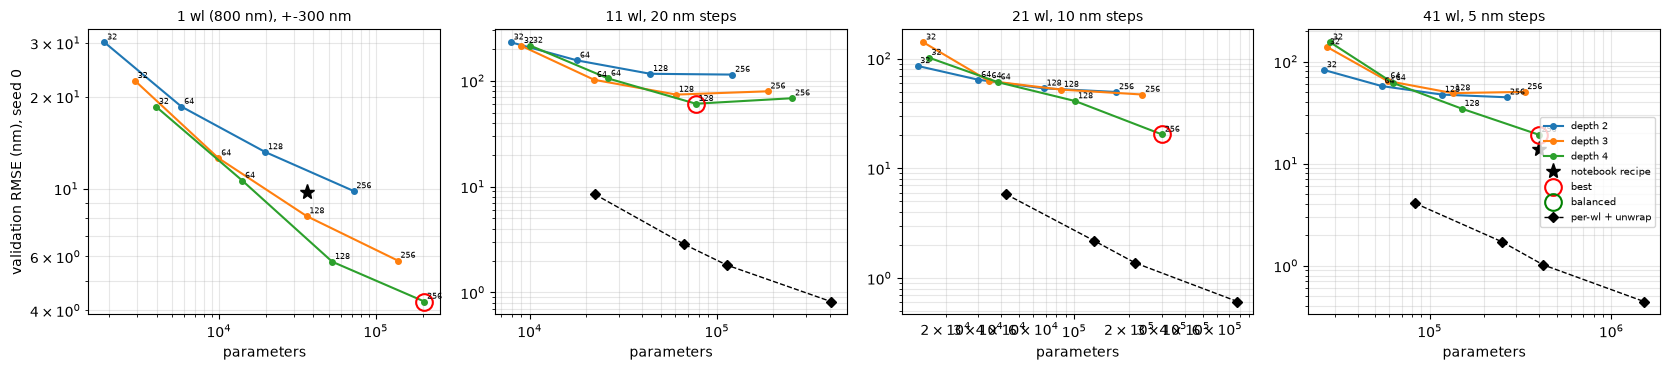

In [35]:
scen_grid = [s for s in ("800nm", "20nm", "10nm", "5nm") if s in set(runs[runs.role == "grid"].scenario)]
plot_hpo_grid(runs, scen_grid, [SCEN_C[s] for s in scen_grid])

## C4. The best of each approach, per scenario

The full-spectrum picks averaged over three seeds (the error bars are the
seed-to-seed range of the mean RMSE), the reference runs, the
single-wavelength run over +-5 um, and the per-wavelength + unwrap
architecture with the lowest held-out RMSE. "gross %" is the share of
estimates off by more than 350 nm: half the shortest wavelength, so a wrong
fringe in the spectral scenarios.

,scenario,pick,config,n_params,seeds,val_rmse,seed_min,seed_max,per_piston,train_s,gross_%
0,800nm,best,4x256 cos3e-4 2000ep,203781,3,4.40,4.27,4.57,"[4.5, 4.6, 3.6, 3.8, 5.6]",28.0,0.000
1,800nm,reference,3x128 const3e-4 500ep,36229,1,9.72,9.72,9.72,"[9.4, 9.8, 10.3, 8.6, 10.5]",10.0,0.000
2,1wl-800,single-wl,4x256 cos3e-4 5000ep,203781,1,2909.67,2909.67,2909.67,"[2905.0, 2892.8, 2918.0, 2919.7, 2913.0]",109.0,93.084
3,20nm,best,4x128 cos3e-4 5000ep,77061,3,63.20,60.73,66.86,"[78.0, 67.5, 25.6, 66.5, 78.4]",275.0,0.130
4,20nm,per-wl + unwrap,3x128 cos3e-4 2000ep per-wl,405614,1,0.82,0.82,0.82,"[0.8, 0.8, 0.7, 0.8, 0.9]",960.0,0.000
5,10nm,best,4x256 cos3e-4 5000ep,301061,3,17.49,10.26,21.89,"[25.9, 16.4, 18.1, 13.2, 13.9]",322.0,0.001
6,10nm,per-wl + unwrap,3x128 cos3e-4 2000ep per-wl,774354,1,0.61,0.61,0.61,"[0.6, 0.6, 0.6, 0.6, 0.6]",1848.0,0.000
7,5nm,best,4x256 cos3e-4 5000ep,398341,3,14.44,8.39,19.18,"[14.0, 13.4, 18.4, 11.9, 14.4]",357.0,0.000
8,5nm,per-wl + unwrap,3x128 cos3e-4 2000ep per-wl,1511834,1,0.44,0.44,0.44,"[0.4, 0.4, 0.4, 0.5, 0.5]",3615.0,0.000
9,5nm,reference,4x256 const3e-4 10000ep,398341,1,13.82,13.82,13.82,"[17.2, 6.4, 21.6, 7.1, 16.7]",554.0,0.002


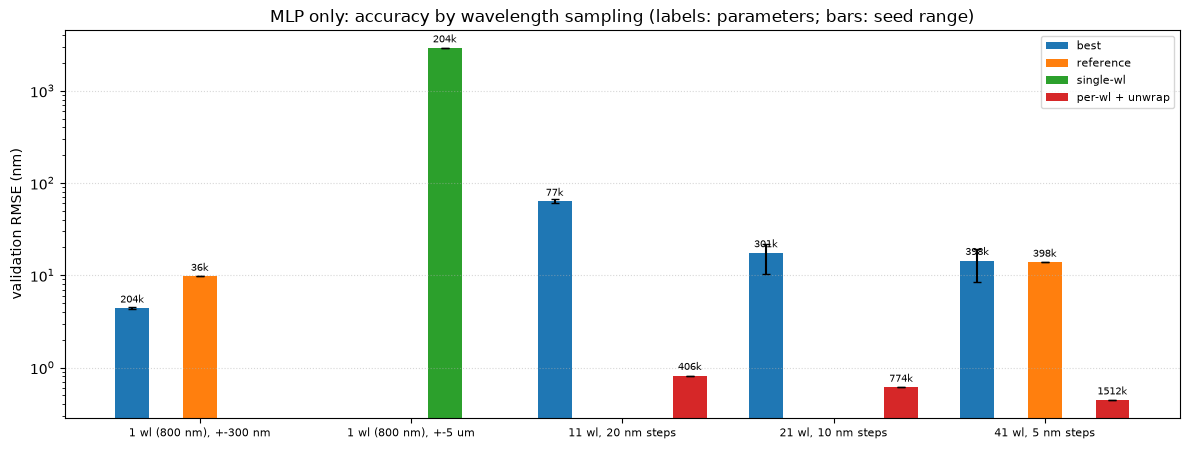

In [36]:
summary_C = hpo_seed_summary(runs, C_VAL_C, HPO_DIR)
summary_C["scenario"] = summary_C.scenario.astype("category").cat.set_categories(list(SCEN_C))
summary_C = summary_C.sort_values(["scenario", "pick"]).reset_index(drop=True)
display(summary_C.round({"val_rmse": 2, "seed_min": 2, "seed_max": 2, "train_s": 0, "gross_%": 3}))
plot_hpo_summary(summary_C, SCEN_C)

## C5. Estimates of the best models (seed 0)

All 5 pistons of every validation sample, estimate against truth.

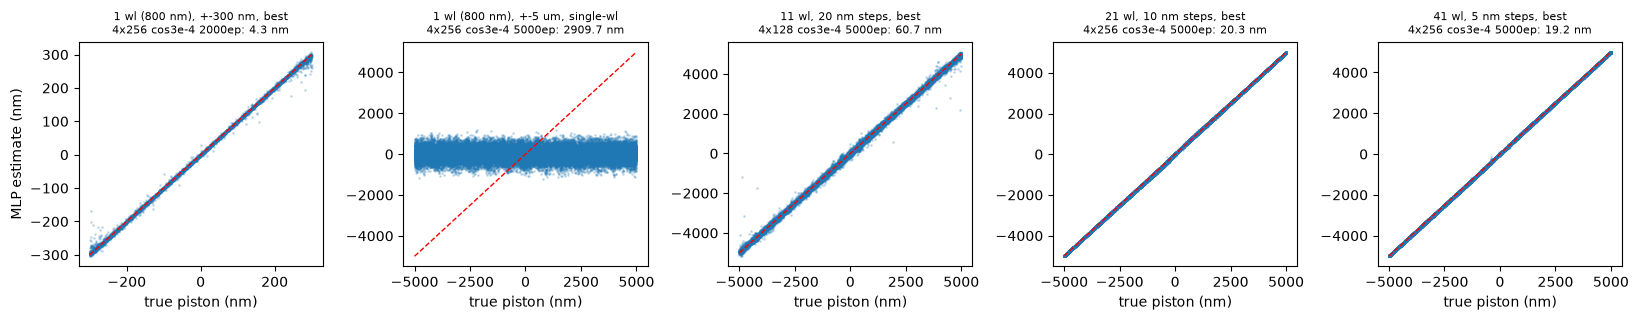

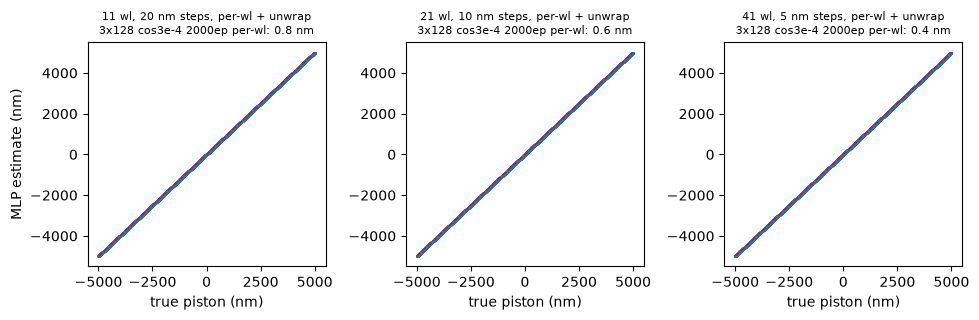

In [37]:
plot_hpo_estimates(summary_C[summary_C.pick.isin(["best", "single-wl"])], runs, C_VAL_C, SCEN_C, HPO_DIR)
plot_hpo_estimates(summary_C[summary_C.pick == "per-wl + unwrap"], runs, C_VAL_C, SCEN_C, HPO_DIR)

## C6. One wavelength: more data vs. bigger models

At 800 nm the search's best configuration (4 x 256, cosine from 3e-4, 2000
epochs) roughly halves the error of the notebook's MLP. Beyond it, quick
one-off tests on the 10000-sample dataset (seed 0, same protocol; not rerun
here) changed little:

| change | validation RMSE |
|---|---|
| 4 x 256, 2000 epochs (the search's best) | 4.27 nm |
| 6000 epochs | 4.04 nm |
| 5 x 256 | 3.98 nm |
| 4 x 512 | 4.14 nm |
| 5 x 256, 6000 epochs | 4.32 nm |
| batch size 64 instead of 128 | 4.30 nm |
| log or square root of the signals | 11.1 / 6.3 nm |
| ensemble of 5 seeds (mean of their estimates) | 3.79 nm |

The held-out loss stays about twice the training loss, so the model is
limited by its 7200 training samples, not by its size. The 800 nm dataset is
cheap to simulate (32 minutes for 50000 samples on the CPU), so
`data/gen/gen_single_50k.py` made one of 50000 samples
(`data/ml/single_800nm_50k.npz`, the same `rng=0` draw, so its first 10000
coefficients are those of Part A). The search's `data800` stage trains the
same 4 x 256 network with 5 seeds on its first 7200, 18000 and 36000 rows,
selecting on its held-out rows 36000-40000 and scoring on its 10000
validation rows.

On those 10000 validation rows the errors turn out to be heavy-tailed. The
median error is a fraction of a nm, but a few configurations in a thousand
are off by tens to hundreds of nm, and they dominate the RMSE. That also
makes any RMSE on 2000 validation rows (Part A, and the `800nm` scenario
above) noisy: the 4 x 256 network trained on the same 7200 rows scores
4.3 nm on Part A's 2000 rows and 9.9 nm on these 10000. So the table also
gives the quantiles of |error| over all pistons. Every model trained on the
first 7200 rows (the notebook recipe included) is rescored here on the same
10000 rows.

In [38]:
import pandas as pd
D50K = "data/ml/single_800nm_50k.npz"
ds50 = ml.LanternDataset.load(D50K)
VA50, CV50 = slice(ds50.n_train, None), ds50.val[1]
seeds_800 = lambda n: [f"800nm-50k-d4w256-cos3e-4-e2000-n{n}-s{s}" for s in range(5)]
models_800 = {"notebook recipe (3x128, 500 ep), 7200": (["800nm-d3w128-const3e-4-e500-s0"], 7200),
              "4x256 cosine 2000 ep, 7200": (seeds_800(7200)[:1], 7200),
              "4x256, 7200, ensemble of 5": (seeds_800(7200), 7200),
              "4x256, 18000, ensemble of 5": (seeds_800(18000), 18000),
              "4x256, 36000": (seeds_800(36000)[:1], 36000),
              "4x256, 36000, ensemble of 5": (seeds_800(36000), 36000)}

In [39]:
robust_800 = pd.DataFrame({k: error_stats(rescore_mlp(ids, HPO_DIR, ds50, VA50, n), CV50)
                           for k, (ids, n) in models_800.items()}).T
display(robust_800.round(2))

,rmse,median,p90,p99,> 50 nm %,piston_2_rmse
"notebook recipe (3x128, 500 ep), 7200",13.55,3.43,11.37,40.78,0.76,11.09
"4x256 cosine 2000 ep, 7200",9.93,0.97,4.06,17.56,0.24,7.39
"4x256, 7200, ensemble of 5",9.13,0.61,2.95,15.62,0.24,6.25
"4x256, 18000, ensemble of 5",7.02,0.31,1.20,5.07,0.11,3.41
"4x256, 36000",6.72,0.74,2.02,4.58,0.06,2.91
"4x256, 36000, ensemble of 5",6.69,0.27,0.83,2.72,0.06,3.07


,n_train,seeds,single,single_min,single_max,ensemble,ensemble_per_piston
0,7200,5,9.48,9.12,9.93,9.13,"[9.7, 10.31, 6.26, 10.07, 9.32]"
1,18000,5,7.24,6.63,7.63,7.02,"[7.94, 7.93, 3.41, 7.55, 8.26]"
2,36000,5,6.85,6.62,7.15,6.69,"[7.73, 7.79, 3.07, 6.64, 8.2]"


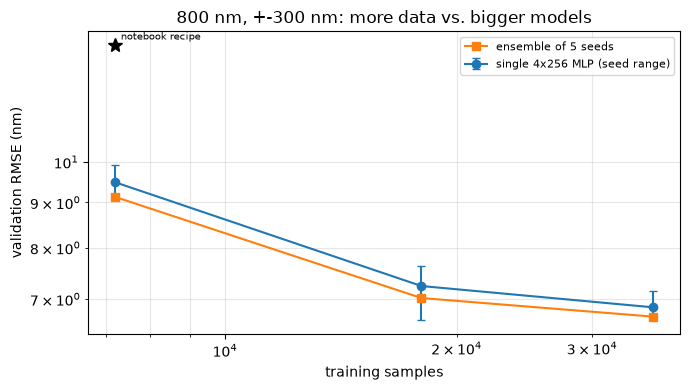

In [40]:
table_800 = data800_table(runs, CV50, HPO_DIR)
display(table_800.round(2))
plot_data800(table_800, ref=[(7200, robust_800.rmse.iloc[0], "notebook recipe")])

## C7. Findings

**One wavelength (800 nm, +-300 nm).** The search's best network, 4 x 256
with a cosine schedule over 2000 epochs, halves the notebook MLP's error. It
scores 4.4 nm over three seeds (4.3-4.6) against 9.7 nm, on Part A's 2000
validation rows. On the 10000-row validation set the gain is larger than
the RMSE shows:

- **Median error:** 3.4 nm becomes 1.0 nm.
- **99th percentile:** 41 nm becomes 18 nm.

With 5x the training data and an ensemble of 5 seeds, it reaches a median of
0.27 nm and a 99th percentile of 2.7 nm, with only 0.06% of the estimates
off by more than 50 nm. The RMSE (13.6 -> 6.7 nm) is held up by those rare
outliers. Bigger networks, longer training and other input transforms did
not help; more data did.

**One wavelength over +-5 um.** No skill (2910 nm, against 2893 nm for
predicting the mean): a single wavelength sees a piston only modulo lambda.

**Several wavelengths, full-spectrum MLP.** It works, but it is hard to
train:

| sampling | best RMSE | seed range |
|---|---|---|
| 20 nm | 63 nm | |
| 10 nm | 17.5 nm | 10-22 nm |
| 5 nm | 14.4 nm | 8-19 nm |

The networks need depth (4 layers): 3-layer ones stay at about 50 nm at 5 nm
steps. The best epoch comes before the end of the cosine schedule, and the
notebook's constant-rate 10000-epoch recipe (13.8 nm) is no worse. Accuracy
here is limited by optimisation and seed variance, not by size.

**Several wavelengths, per-wavelength MLPs + unwrap.** Far better, and
stable:

| sampling | 3 x 128 per wavelength | 3 x 64 per wavelength |
|---|---|---|
| 20 nm | 0.82 nm | 1.8 nm (113k parameters) |
| 10 nm | 0.61 nm | 1.4 nm |
| 5 nm | 0.44 nm | 1.0 nm |

There are no wrong fringes in any of them, against 1.64 nm for the OMP
version of B4. Each per-wavelength model only has to learn a smooth,
bounded function (the phasor) over one fringe, and the unwrap does the rest
by construction. Even 20 nm steps with 3 x 64 networks (113k parameters in
all) beat every full-spectrum MLP by an order of magnitude, including the
5 nm 4 x 256 one (398k). The error still falls with the network size
(wrapped RMSE per wavelength 23 -> 11 -> 6.7 -> 3.0 nm), so larger
per-wavelength networks are the obvious next step.

**Piston 2** is the easiest piston everywhere except in the full-spectrum
MLPs: about 3 nm against 8 nm at 800 nm with 36000 samples, and the lowest
wrapped error at every wavelength. `piston2.ipynb` looks into why.

# Summary

Every model of Parts A and B, and the best MLP of each Part C scenario
(averaged over seeds). The parts are not directly comparable: different
ranges (+-300 nm vs +-5 um), signals (camera at 800 nm with unit coupled
power vs. channel power fractions at 41 wavelengths) and training-set sizes,
and Part C keeps 10% of the training split for model selection.

In [41]:
print(f"{'':36s} {'mean RMSE':>10s}   per piston [nm]")
for part, res in [("A  800 nm, +-300 nm", RESULTS_A), ("B  41 wl, +-5 um", RESULTS_B)]:
    print(part)
    for m, r in sorted(res.items(), key=lambda kv: kv[1].mean()):
        print(f"  {m:34s} {r.mean():10.2f}   {np.round(r, 2)}")
print("C  MLP only: best full-spectrum configuration, and per-wavelength + unwrap")
for _, r in summary_C[summary_C.pick.isin(["best", "single-wl", "per-wl + unwrap"])].iterrows():
    name = f"{SCEN_C[r.scenario]}, {'per-wl ' if 'unwrap' in r.pick else ''}{r.config.split()[0]}"
    print(f"  {name:34s} {r.val_rmse:10.2f}   {r.per_piston}")

                                      mean RMSE   per piston [nm]
A  800 nm, +-300 nm
  zern-omp-K1282                           8.41   [8.91 7.89 8.27 8.04 8.94]
  MLP                                      8.98   [9.15 9.43 9.24 7.64 9.45]
  zern-d3                                 11.34   [12.29 10.89  8.88 11.38 13.26]
  fiber-d3                                11.49   [12.62 10.88  9.08 11.3  13.55]
  elastic-d3                              25.47   [26.15 24.24 25.51 22.95 28.51]
  kNN                                     29.42   [30.67 30.2  27.13 29.22 29.88]
  zern-omp-K500                           29.48   [29.36 29.67 29.44 26.5  32.44]
B  41 wl, +-5 um
  per-wl OMP + unwrap                      1.64   [1.88 1.99 0.45 1.9  1.96]
  MLP (all wl)                            10.24   [ 6.53  5.11 25.2   6.84  7.52]
  fiber-ridge-d2                         969.00   [ 983.26 1060.86  733.52 1021.48 1045.85]
  kNN                                   1230.98   [1255.73 1213.16 1202.58 1254.91